#**Phân tích Hiệu suất Sản phẩm & Tối ưu hóa Tỷ lệ Chuyển đổi (CR Optimization)**

# Import Library & Import Data

In [ ]:
# Data Processing
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Datetime Standardize
import datetime

In [ ]:
import sys
import matplotlib

print(f"Python version: {sys.version.split()[0]}")
print(f"pandas version: {pd.__version__}")
print(f"matplotlib version: {matplotlib.__version__}")
print(f"numpy version: {np.__version__}")

Python version: 3.13.18
pandas version: 2.2.3
matplotlib version: 3.10.0
numpy version: 2.4.6


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Exploratory Data Analysis

##**Phần 1: Phân tích Doanh thu và Hoàn tiền (Revenue & Refund Analysis)**


cần tính toán:
1. **Gross Revenue**: Tổng doanh thu từ việc bán hàng.
2. **Refund Rate**: Tỷ lệ đơn hàng bị hoàn tiền.
3. **Net Revenue**: Doanh thu thực tế sau khi trừ đi số tiền hoàn trả.

In [ ]:
products = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/dataset/Pareto/Bản sao của products.csv')
products.head()

,product_id,created_at,product_name
0,1,2012-03-19 08:00:00,The Original Mr. Fuzzy
1,2,2013-01-06 13:00:00,The Forever Love Bear
2,3,2013-12-12 09:00:00,The Birthday Sugar Panda
3,4,2014-02-05 10:00:00,The Hudson River Mini bear


In [ ]:
orders = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/dataset/Pareto/Bản sao của order_items.csv')
orders.head()

,order_item_id,created_at,order_id,product_id,is_primary_item,price_usd,cogs_usd
0,1,2012-03-19 10:42:46,1,1,1,49.99,19.49
1,2,2012-03-19 19:27:37,2,1,1,49.99,19.49
2,3,2012-03-20 06:44:45,3,1,1,49.99,19.49
3,4,2012-03-20 09:41:45,4,1,1,49.99,19.49
4,5,2012-03-20 11:28:15,5,1,1,49.99,19.49


In [ ]:
refunds = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/dataset/Pareto/Bản sao của order_item_refunds.csv')
refunds.head()

,order_item_refund_id,created_at,order_item_id,order_id,refund_amount_usd
0,1,2012-04-06 11:32:43,57,57,49.99
1,2,2012-04-13 01:09:43,74,74,49.99
2,3,2012-04-15 07:03:48,71,71,49.99
3,4,2012-04-17 20:00:37,118,118,49.99
4,5,2012-04-22 20:53:49,116,116,49.99


In [ ]:
#merge đơn hàng + sản phẩm
order_data = orders.merge(products, on = 'product_id', how = 'left')
# thêm refund
order_summary = order_data.merge(refunds[['order_item_id', 'refund_amount_usd']], on='order_item_id', how='left')
order_summary.head(3)

,order_item_id,created_at_x,order_id,product_id,is_primary_item,price_usd,cogs_usd,created_at_y,product_name,refund_amount_usd
0,1,2012-03-19 10:42:46,1,1,1,49.99,19.49,2012-03-19 08:00:00,The Original Mr. Fuzzy,NaN
1,2,2012-03-19 19:27:37,2,1,1,49.99,19.49,2012-03-19 08:00:00,The Original Mr. Fuzzy,NaN
2,3,2012-03-20 06:44:45,3,1,1,49.99,19.49,2012-03-19 08:00:00,The Original Mr. Fuzzy,NaN


In [ ]:
#những đơn ko bị hoàn tiền thì xử lý cho bằng 0
order_summary['refund_amount_usd'] = order_summary['refund_amount_usd'].fillna(0)
order_summary['is_refunded'] = order_summary['refund_amount_usd'] > 0
order_summary['net_revenue'] = order_summary['price_usd'] - order_summary['refund_amount_usd']
order_summary.head(3)

,order_item_id,created_at_x,order_id,product_id,is_primary_item,price_usd,cogs_usd,created_at_y,product_name,refund_amount_usd,is_refunded,net_revenue
0,1,2012-03-19 10:42:46,1,1,1,49.99,19.49,2012-03-19 08:00:00,The Original Mr. Fuzzy,0.0,False,49.99
1,2,2012-03-19 19:27:37,2,1,1,49.99,19.49,2012-03-19 08:00:00,The Original Mr. Fuzzy,0.0,False,49.99
2,3,2012-03-20 06:44:45,3,1,1,49.99,19.49,2012-03-19 08:00:00,The Original Mr. Fuzzy,0.0,False,49.99


In [ ]:
#nhóm theo sản phẩm tính các chỉ số cần thiết
result = order_summary.groupby(by = 'product_name')\
                      .agg(gross_revenue =('price_usd','sum'),
                            total_refund_amount=('refund_amount_usd', 'sum'),
                           net_revenue=('net_revenue', 'sum'),
                           total_orders=('order_item_id', 'count'),
                            refunded_orders=('is_refunded', 'sum')).reset_index()
result

,product_name,gross_revenue,total_refund_amount,net_revenue,total_orders,refunded_orders
0,The Birthday Sugar Panda,229260.15,13842.99,215417.16,4985,301
1,The Forever Love Bear,347702.04,7738.71,339963.33,5796,129
2,The Hudson River Mini bear,150489.82,1919.36,148570.46,5018,64
3,The Original Mr. Fuzzy,1211057.74,61837.63,1149220.11,24226,1237


In [ ]:
#tỉnh tỉ lệ hoàn tiền
result['refund_rate (%)']=result['refunded_orders']/result['total_orders']*100

# Xếp hạng theo doanh thu thuần (Net Revenue)
result = result.sort_values(by='net_revenue', ascending=False)
result

,product_name,gross_revenue,total_refund_amount,net_revenue,total_orders,refunded_orders,refund_rate (%)
3,The Original Mr. Fuzzy,1211057.74,61837.63,1149220.11,24226,1237,5.106084
1,The Forever Love Bear,347702.04,7738.71,339963.33,5796,129,2.225673
0,The Birthday Sugar Panda,229260.15,13842.99,215417.16,4985,301,6.038114
2,The Hudson River Mini bear,150489.82,1919.36,148570.46,5018,64,1.275409


/tmp/ipykernel_1442/1193268538.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='net_revenue', y='product_name', data=result, palette = 'Set2')


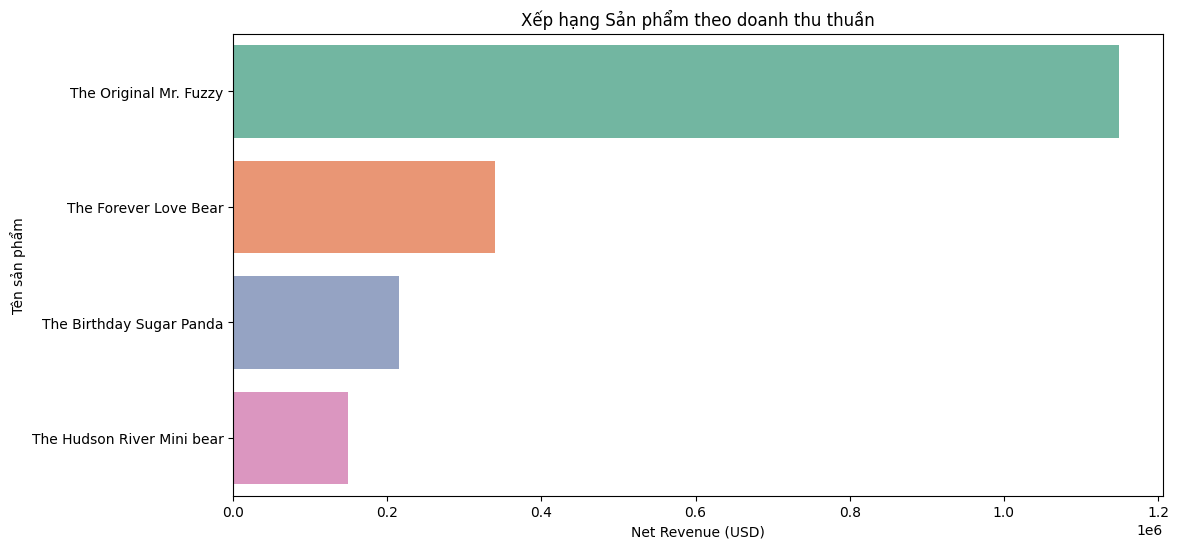

In [ ]:
#chart 1: SS doanh thu thuần
plt.figure(figsize=(12, 6))
sns.barplot(x='net_revenue', y='product_name', data=result, palette = 'Set2')
plt.title('Xếp hạng Sản phẩm theo doanh thu thuần')
plt.xlabel('Net Revenue (USD)')
plt.ylabel('Tên sản phẩm')
plt.show()

/tmp/ipykernel_1442/1805896882.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='refund_rate (%)', y='product_name', data=result, palette='Set1')


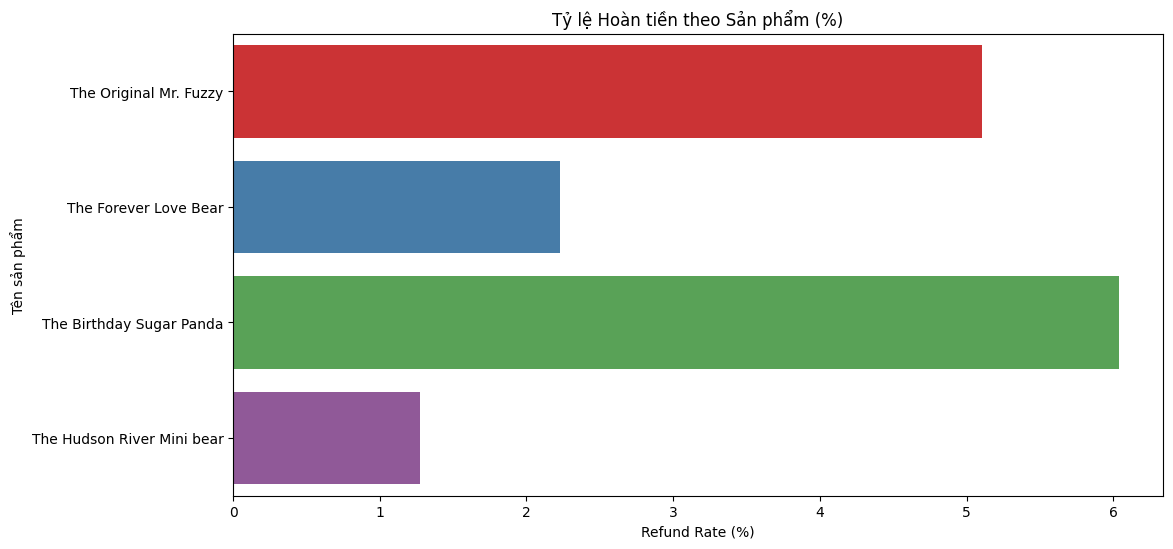

In [ ]:
#chart 2: tỷ lệ hoàn tiền theo sp
plt.figure(figsize=(12, 6))
sns.barplot(x='refund_rate (%)', y='product_name', data=result, palette='Set1')
plt.title('Tỷ lệ Hoàn tiền theo Sản phẩm (%)')
plt.xlabel('Refund Rate (%)')
plt.ylabel('Tên sản phẩm')
plt.show()

###***Nhận xét***


*  **The Original Mr. Fuzzy**	có doanh thu thuần cao nhất (vượt xa các sản phẩm còn lại), đồng thời, cũng là sản phẩm có tỷ lệ hoàn tiền cao thứ 2 (khoảng 5,1%)
*   **The Birthday Sugar Panda**	có tỷ lệ hoàn tiền cao nhất, doanh thu ở mức thấp --> cần xem lại chất lượng sp



##**Phần 2: Phân tích Phễu theo Sản phẩm (Product-Specific Funnel)**

Mục tiêu: So sánh trải nghiệm khách hàng giữa **"The Original Mr. Fuzzy"** và **"The Forever Love Bear"** từ trang `/products` đến khi mua hàng.

In [ ]:
pageviews = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/dataset/Pareto/Bản sao của website_pageviews.csv')
sessions = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/dataset/Pareto/Bản sao của website_sessions.csv')

In [ ]:
pageviews

,website_pageview_id,created_at,website_session_id,pageview_url
0,1,2012-03-19 08:04:16,1,/home
1,2,2012-03-19 08:16:49,2,/home
2,3,2012-03-19 08:26:55,3,/home
3,4,2012-03-19 08:37:33,4,/home
4,5,2012-03-19 09:00:55,5,/home
...,...,...,...,...
1188119,1188120,2015-03-19 07:57:32,472866,/shipping
1188120,1188121,2015-03-19 07:58:13,472870,/the-original-mr-fuzzy
1188121,1188122,2015-03-19 07:59:07,472866,/billing-2
1188122,1188123,2015-03-19 07:59:08,472871,/home


In [ ]:
pageviews['pageview_url'].unique()

array(['/home', '/products', '/the-original-mr-fuzzy', '/cart',
       '/shipping', '/billing', '/thank-you-for-your-order', '/lander-1',
       '/billing-2', '/the-forever-love-bear', '/lander-2', '/lander-3',
       '/the-birthday-sugar-panda', '/lander-4', '/lander-5',
       '/the-hudson-river-mini-bear'], dtype=object)

In [ ]:
# URLs cần phân tích
product_pages = {
    'Mr. Fuzzy': '/the-original-mr-fuzzy',
    'Love Bear': '/the-forever-love-bear'}


In [ ]:
# Lấy từ thời gian Love Bear ra mắt (2013-01-06 13:00:00) để so sánh công bằng, do Mr.Fuzzy đã ra mắt trước
pageviews_filtered = pageviews[pageviews['created_at'] > '2013-01-06 13:00:00' ]
pageviews_filtered.head(2)

,website_pageview_id,created_at,website_session_id,pageview_url
139063,139064,2013-01-06 13:00:17,63558,/lander-1
139064,139065,2013-01-06 13:01:15,63555,/shipping


In [ ]:
def get_funnel(df, product_name, product_url):
    # 1. Lấy tất cả các session đã từng truy cập vào trang danh mục /products
    sessions_at_products = df[df['pageview_url'] == '/products']['website_session_id'].unique()
    df_filtered = df[df['website_session_id'].isin(sessions_at_products)]

    # Bước 1: Số lượng session truy cập vào trang danh mục sản phẩm (/products)
    step_1_products = len(sessions_at_products)

    # Bước 2: Số lượng session đi từ trang danh mục vào xem trang chi tiết của sản phẩm cụ thể
    sessions_at_detail = df_filtered[df_filtered['pageview_url'] == product_url]['website_session_id'].unique()
    step_2_detail = len(sessions_at_detail)

    # Lọc tiếp df chỉ giữ các session đã xem chi tiết sản phẩm này để tính các bước tiếp theo
    df_detail_sessions = df_filtered[df_filtered['website_session_id'].isin(sessions_at_detail)]

    # Bước 3: Xem giỏ hàng (/cart)
    sessions_at_cart = df_detail_sessions[df_detail_sessions['pageview_url'] == '/cart']['website_session_id'].unique()
    step_3_cart = len(sessions_at_cart)

    df_detail_cart = df_filtered[df_filtered['website_session_id'].isin(sessions_at_cart)]

    # Bước 4: Hoàn tất đơn hàng (/thank-you-for-your-order)
    sessions_at_thanks = df_detail_cart[df_detail_cart['pageview_url'] == '/thank-you-for-your-order']['website_session_id'].unique()
    step_4_thanks = len(sessions_at_thanks)

    # Tạo DataFrame kết quả chỉ với 4 bước chính
    funnel_df = pd.DataFrame({
        'Step': [
            '1. Products',
            '2. View Product Detail',
            '3. Add to Cart',
            '4. Thank you (Purchase)'
        ],
        'Sessions': [
            step_1_products,
            step_2_detail,
            step_3_cart,
            step_4_thanks
        ]
    })

    # Tính tỷ lệ chuyển đổi lũy tiến (so với bước đầu tiên /products)
    funnel_df['Cumulative_CR (%)'] = (funnel_df['Sessions'] / step_1_products * 100).round(2)

    # Tính tỷ lệ chuyển đổi qua từng bước lẻ (so với bước ngay trước đó)
    funnel_df['Dropoff_Rate (%)'] = 100 - (funnel_df['Sessions'] / funnel_df['Sessions'].shift(1) * 100).fillna(100).round(2)
    funnel_df['Step_CR (%)'] = (funnel_df['Sessions'] / funnel_df['Sessions'].shift(1) * 100).fillna(100).round(2)

    return funnel_df

In [ ]:
# phễu chuyển đổi cho 2 sản phẩm chính
print("=== PHỄU CHUYỂN ĐỔI: MR. FUZZY ===")
mr_fuzzy_funnel = get_funnel(pageviews_filtered, 'Mr. Fuzzy', '/the-original-mr-fuzzy')
display(mr_fuzzy_funnel)

print("\n=== PHỄU CHUYỂN ĐỔI: LOVE BEAR ===")
love_bear_funnel = get_funnel(pageviews_filtered, 'Love Bear', '/the-forever-love-bear')
display(love_bear_funnel)

=== PHỄU CHUYỂN ĐỔI: MR. FUZZY ===


,Step,Sessions,Cumulative_CR (%),Dropoff_Rate (%),Step_CR (%)
0,1. Products,231193,100.00,0.00,100.00
1,2. View Product Detail,140851,60.92,39.08,60.92
2,3. Add to Cart,60533,26.18,57.02,42.98
3,4. Thank you (Purchase),21208,9.17,64.96,35.04



=== PHỄU CHUYỂN ĐỔI: LOVE BEAR ===


,Step,Sessions,Cumulative_CR (%),Dropoff_Rate (%),Step_CR (%)
0,1. Products,231193,100.00,0.00,100.00
1,2. View Product Detail,26033,11.26,88.74,11.26
2,3. Add to Cart,14485,6.27,44.36,55.64
3,4. Thank you (Purchase),4803,2.08,66.84,33.16


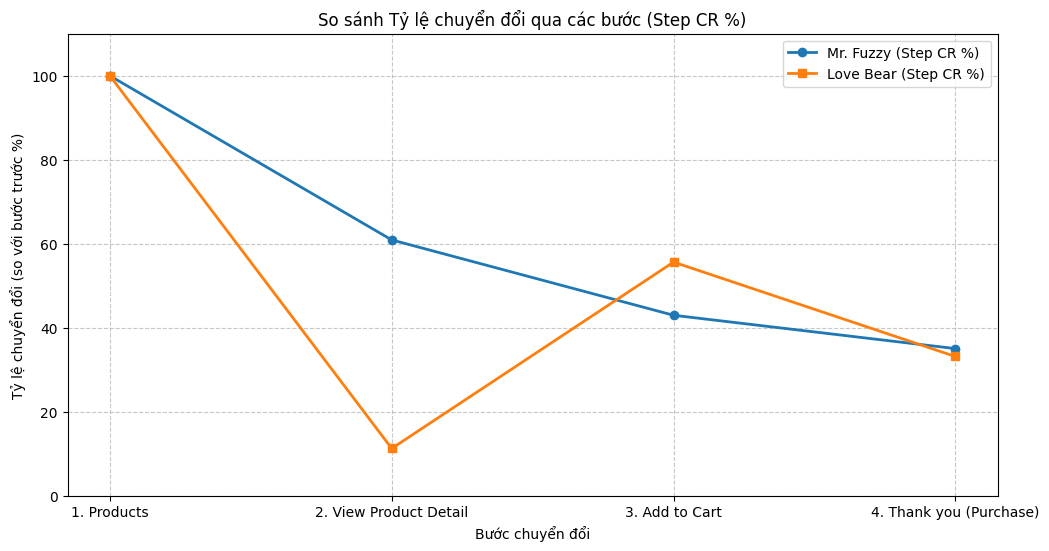

In [ ]:
# Trực quan hóa 3: So sánh CTR giữa 2 sản phẩm
plt.figure(figsize=(12, 6))
plt.plot(mr_fuzzy_funnel['Step'], mr_fuzzy_funnel['Step_CR (%)'], marker='o', label='Mr. Fuzzy (Step CR %)', linewidth=2)
plt.plot(love_bear_funnel['Step'], love_bear_funnel['Step_CR (%)'], marker='s', label='Love Bear (Step CR %)', linewidth=2)

plt.title('So sánh Tỷ lệ chuyển đổi qua các bước (Step CR %)')
plt.ylabel('Tỷ lệ chuyển đổi (so với bước trước %)')
plt.xlabel('Bước chuyển đổi')
plt.ylim(0, 110)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

###***Nhận xét:***

* Khách hàng quan tâm đến sản phẩm Mr. Fuzzy hơn, trong khi Love Bear có CR là 11,26% --> điểm nghẽn khiến Love Bear có doanh thu thấp
* Mr.Fuzzy có tỷ lệ "chốt đơn" (từ giỏ hàng đến mua hàng) tốt hơn một chút so với Love Bear, tuy nhiên cả 2 sản phẩm này đều có CR thấp, chỉ khoảng 33-35% --> tỷ lệ khách hàng hoàn tất giao dịch sau khi thêm sản phẩm vào giỏ hàng còn thấp. => cần kiểm tra quy trình checkout, chi phí vận chuyển, phương thức thanh toán và các yếu tố có thể khiến khách hàng từ bỏ giỏ hàng.
* dù vậy, Love Bear có CR từ trang product detail đến thêm vào giỏ hàng (55,64%) cao hơn nhiều so với Mr. Fuzzy (42,98%) => nghiên cứu những yếu tố trên trang Love Bear có thể hỗ trợ hành vi thêm vào giỏ hàng (ví dụ như thiết kế trang ổn định, dễ theo dõi), sau đó thử nghiệm áp dụng cho Mr. Fuzzy (A/B testing giao diện)




#RECOMMENDATION



* Nên tập trung ngân sách quảng cáo vào sản phẩm **Mr. Fuzzy** do sản phẩm này có doanh thu vượt trội + tỷ lệ chuyển đổi từ trang sản phẩm vào trang chi tiết cao

--> chứng tỏ Mr.Fuzzy có sức hút khi khách hàng lướt xem trang danh mục
* để giảm thiểu tỷ lệ thoát, cần: cải thiện cách hiển thị sản phẩm Love Bear tại trang danh mục sản phẩm, có thể thêm ưu đãi nổi bật hoặc hình ảnh bắt mắt hơn

